# Sampling directional runs by information

Positive and negative contributions are accumulated separately, and the run measure keeps the larger total:

$$
x_i^+=\max(x_i,0),\qquad x_i^-=\max(-x_i,0),\qquad
R_n=\max\left\{\sum_{i=1}^{n}x_i^+,\sum_{i=1}^{n}x_i^-\right\}.
$$

Here, $x_i$ is a signed contribution; $x_i^+$ is its positive part; $x_i^-$ is the magnitude of its negative part. $n$ is the current record count; $R_n$ is the larger of cumulative positive and cumulative negative contributions.

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display


def compact_float_format(number_format=None):
    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value


def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch(r"[+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?", rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return "0"
    if ("." in rendered or "e" in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered


def compact_numeric_text(text):
    pattern = r"(?<![0-9.eE])([+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])"
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)


def compact_table_latex(latex):
    return compact_numeric_text(latex)


def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + "</div>"


def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)

from pathlib import Path
import sys
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image

ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
import hashlib

DATA_URL = "https://data.binance.vision/data/spot/monthly/klines/BTCUSDT/1m/BTCUSDT-1m-2021-01.zip"
DATA_DIR = ROOT / "data" / "public" / "binance"
DATA_PATH = ensure_dataset(ROOT, "binance_btcusdt")
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
expected_data_hash = "9364A063EFA0604D5B9D2536FB68F922DA5AFA3D8F94A26A527471A1E2F87801"
data_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest().upper()
assert data_hash == expected_data_hash
public_columns = ["Open time", "Open", "High", "Low", "Close", "Volume", "Close time", "Quote volume", "Trades", "Buyer base volume", "Buyer quote volume", "Unused"]
raw = pd.read_csv(DATA_PATH, compression="zip", header=None, names=public_columns, nrows=10080)
raw["time"] = pd.to_datetime(raw["Open time"], unit="ms", utc=True).dt.tz_convert(None)
raw = raw.rename(columns={"Close": "close", "Volume": "volume", "Quote volume": "quote_volume", "Trades": "trades"})
raw = raw.sort_values("time").drop_duplicates("time").reset_index(drop=True)

from RiskLabAI.data.structures.imbalance_bars import FixedImbalanceBars
from RiskLabAI.data.structures.run_bars import ExpectedRunBars, FixedRunBars
from RiskLabAI.utils.constants import CUMULATIVE_BUY_THETA, CUMULATIVE_SELL_THETA, EXPECTED_BUY_IMBALANCE, EXPECTED_BUY_TICKS_PROPORTION, EXPECTED_SELL_IMBALANCE, EXPECTED_TICKS_NUMBER

FIGURES = ROOT / "outputs" / "figures" / "05_event_based_financial_time"
TABLES = ROOT / "outputs" / "tables" / "05_event_based_financial_time"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

palette = {
    "background": "#FFFFFF",
    "axes": "#FFFFFF",
    "text": "#1B365D",
    "cyan": "#0072B2",
    "amber": "#C76D00",
    "green": "#00866A",
    "rose": "#B83B3B",
    "violet": "#A03A78",
    "grid": "#D9DEE5",
}
plt.rcParams.update({
    "font.family": "Times New Roman",
    "font.size": 11.5,
    "figure.facecolor": palette["background"],
    "axes.facecolor": palette["axes"],
    "axes.edgecolor": palette["text"],
    "axes.labelcolor": palette["text"],
    "axes.titlecolor": palette["text"],
    "xtick.color": palette["text"],
    "ytick.color": palette["text"],
    "text.color": palette["text"],
    "grid.color": palette["grid"],
    "grid.linestyle": ":",
    "legend.facecolor": palette["axes"],
    "legend.edgecolor": palette["grid"],
    "savefig.facecolor": palette["background"],
})

BAR_COLUMNS = [
    "Time", "Last record", "Open", "High", "Low", "Close",
    "Volume", "Buy volume", "Sell volume", "Records", "Dollar value", "Rule level",
]

def save_table(frame, stem, caption, label, float_format="%.6f", fit=True):
    frame.to_csv(TABLES / f"{stem}.csv", index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position="H"))
    if fit:
        latex = latex.replace(r"\begin{tabular}", r"\begin{adjustbox}{max width=\textwidth}\begin{tabular}", 1).replace(r"\end{tabular}", r"\end{tabular}\end{adjustbox}", 1)
    else:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{tabular}", 1)
    (TABLES / f"{stem}.tex").write_text(latex, encoding="utf-8")

def bar_frame(rows):
    frame = pd.DataFrame(rows, columns=BAR_COLUMNS)
    if not frame.empty:
        frame["Time"] = pd.to_datetime(frame["Time"])
    return frame

raw = raw.sort_values("time").dropna(subset=["time", "close", "volume"]).reset_index(drop=True)
observations = list(raw[["time", "close", "volume"]].itertuples(index=False, name=None))
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": "#FFFFFF", "axes.facecolor": "#FFFFFF", "axes.edgecolor": "#5C6670", "axes.labelcolor": "#1B365D", "axes.titlecolor": "#1B365D", "axes.titleweight": "bold", "xtick.color": "#5C6670", "ytick.color": "#5C6670", "text.color": "#1B365D", "grid.color": "#D9DEE5", "grid.linestyle": ":", "grid.linewidth": 0.8, "legend.facecolor": "#FFFFFF", "legend.edgecolor": "#D9DEE5", "legend.framealpha": 0.96, "savefig.facecolor": "#FFFFFF", "savefig.transparent": False, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == "3.2.0"


## How signed ticks cancel or accumulate

Imbalance lets opposite signs cancel, while the run measure keeps positive and negative accumulation separate:

$$
\theta_n=\sum_{i=1}^{n}x_i,\qquad
R_n=\max\left\{\sum_{i=1}^{n}x_i^+,\sum_{i=1}^{n}x_i^-\right\}.
$$

Here, $\theta_n$ is net imbalance through record $n$; $x_i$ is a signed contribution; $x_i^+,x_i^-$ are its positive and negative parts. $R_n$ is the larger one-sided accumulated total; $i$ labels records; $n$ is the current record count.

,Quantity,Value
0,Final net imbalance,0
1,Largest absolute net imbalance,6
2,Final positive count,12
3,Final negative count,12
4,Final run measure,12


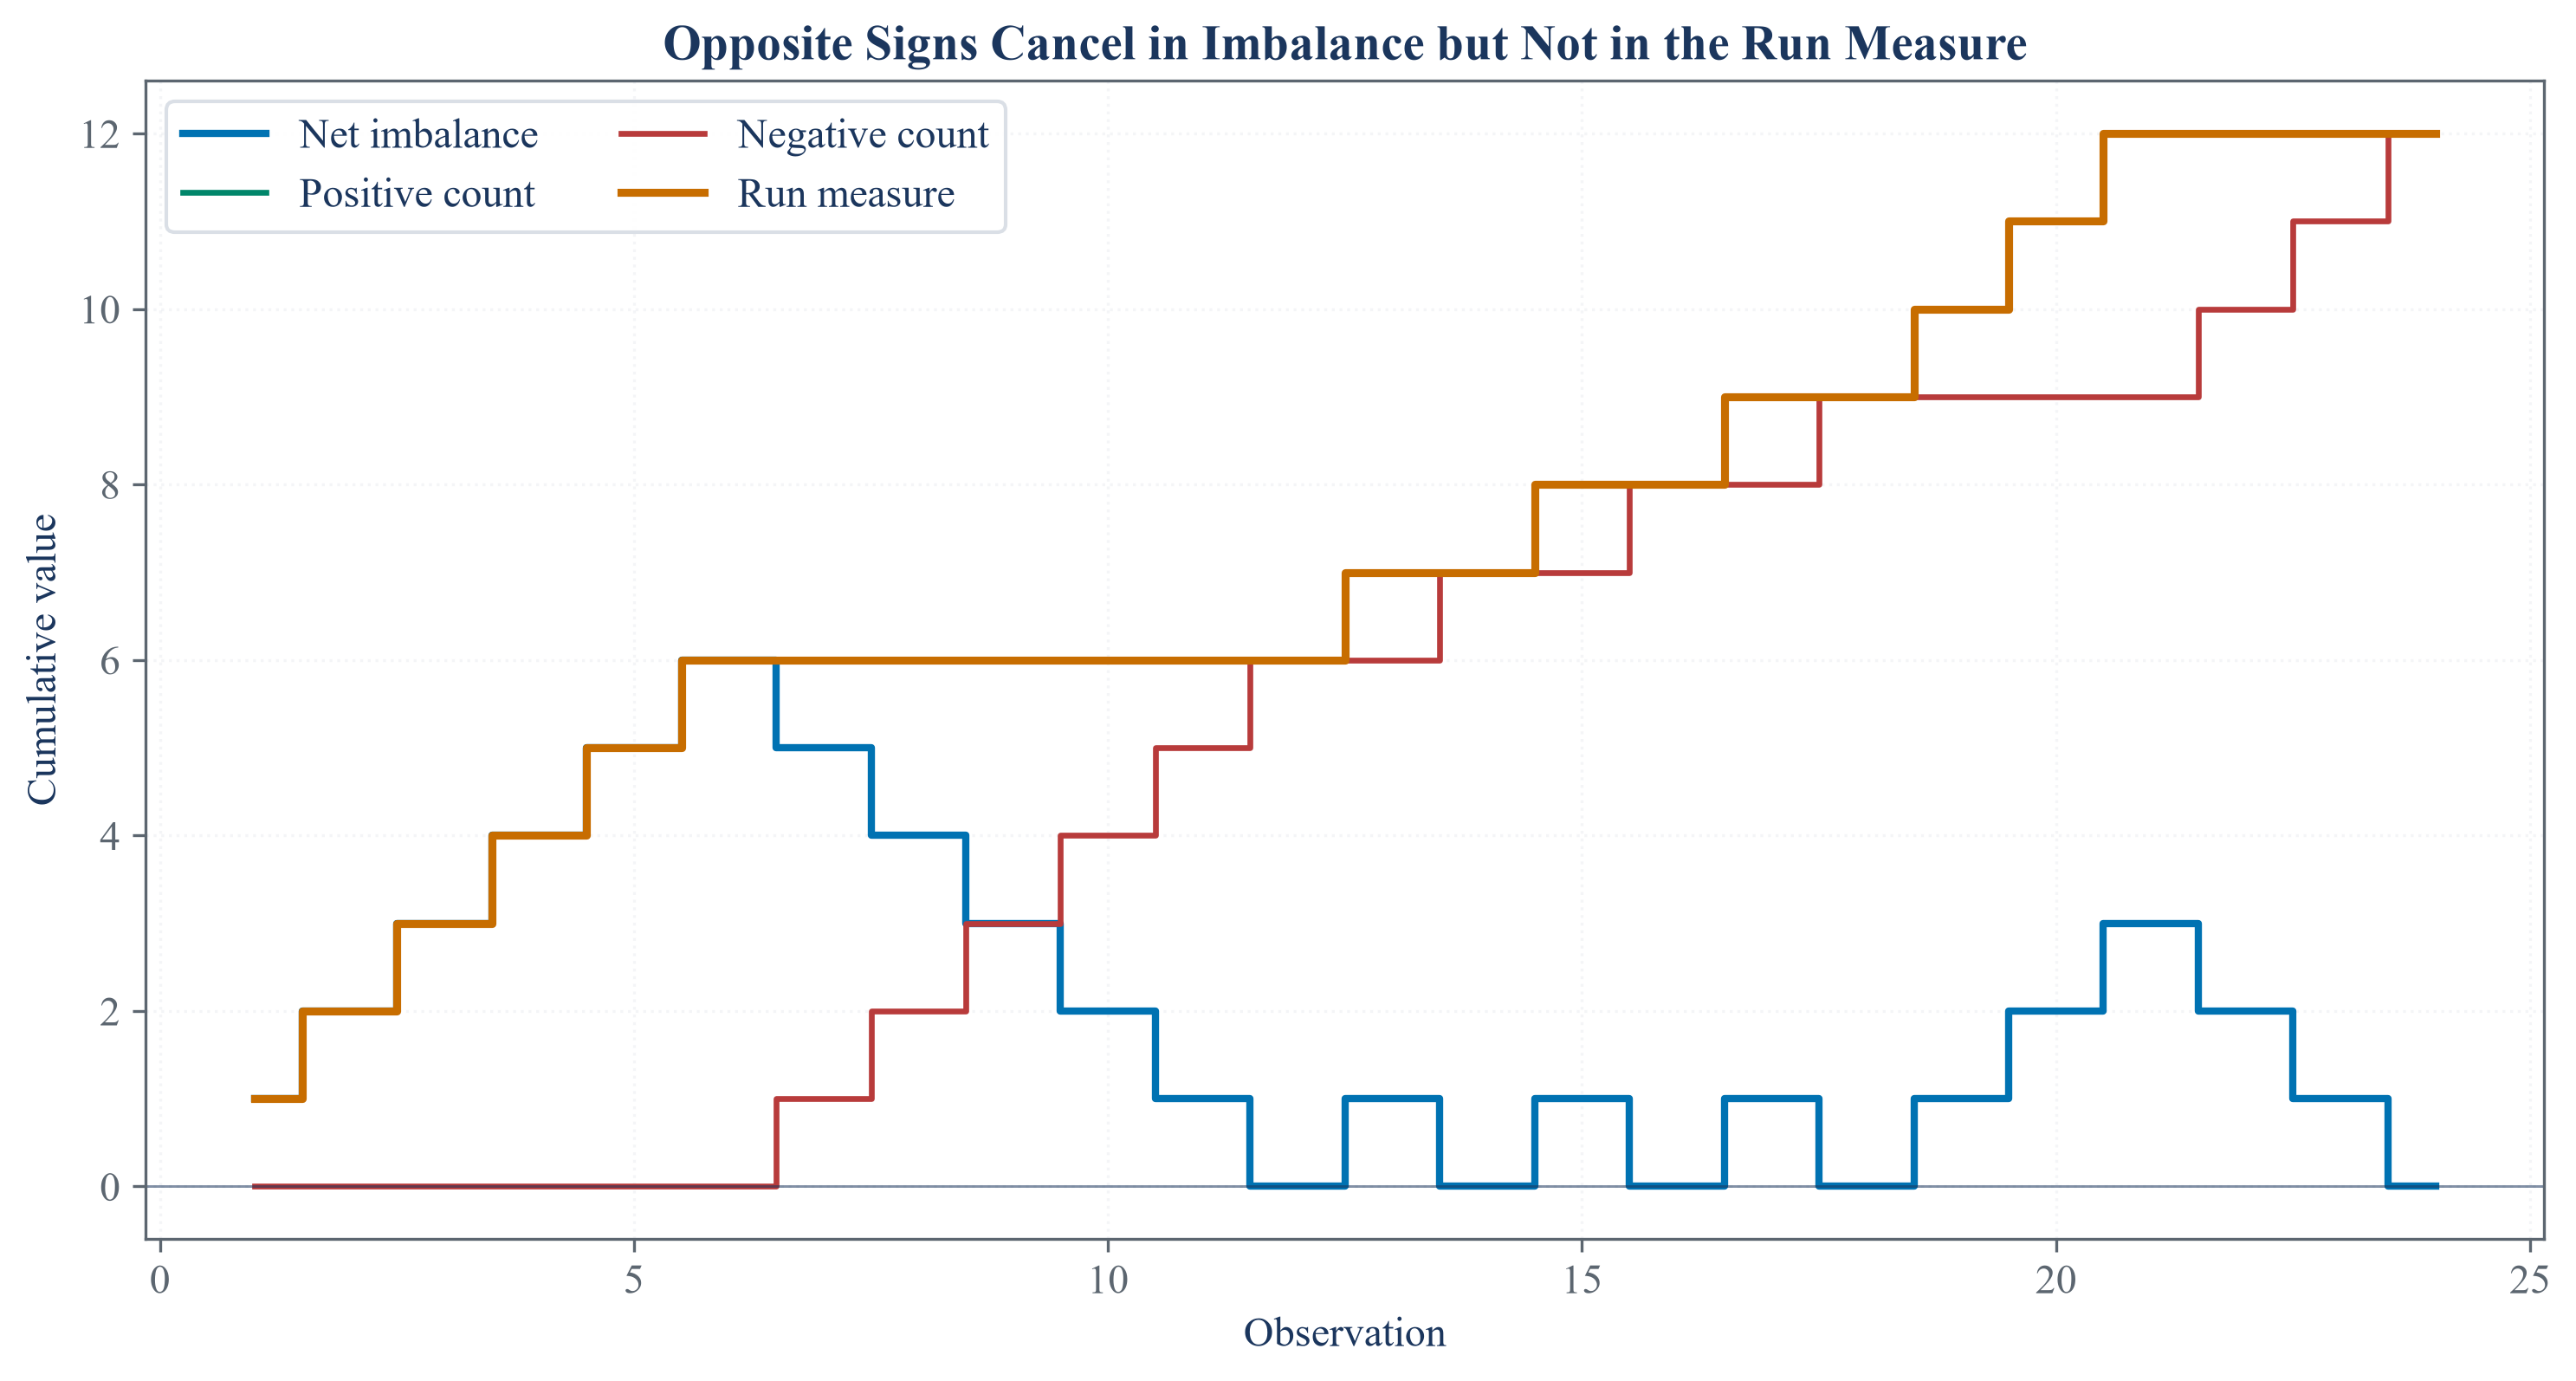

In [2]:
signs = np.array([1, 1, 1, 1, 1, 1, -1, -1, -1, -1, -1, -1, 1, -1, 1, -1, 1, -1, 1, 1, 1, -1, -1, -1])
net_imbalance = np.cumsum(signs)
positive_count = np.cumsum(signs > 0)
negative_count = np.cumsum(signs < 0)
run_measure = np.maximum(positive_count, negative_count)

controlled_comparison = pd.DataFrame({
    "Quantity": ["Final net imbalance", "Largest absolute net imbalance", "Final positive count", "Final negative count", "Final run measure"],
    "Value": [net_imbalance[-1], np.abs(net_imbalance).max(), positive_count[-1], negative_count[-1], run_measure[-1]],
})
save_table(controlled_comparison, "controlled_run_comparison", "Net imbalance permits cancellation, while the run measure keeps the two sides separate.", "tab:controlled-run-comparison", fit=False)
display(controlled_comparison)

figure, axis = plt.subplots(figsize=(9.8, 5.2), constrained_layout=True)
positions = np.arange(1, signs.size + 1)
axis.step(positions, net_imbalance, where="mid", color=palette["cyan"], linewidth=2.0, label="Net imbalance")
axis.step(positions, positive_count, where="mid", color=palette["green"], linewidth=1.6, label="Positive count")
axis.step(positions, negative_count, where="mid", color=palette["rose"], linewidth=1.6, label="Negative count")
axis.step(positions, run_measure, where="mid", color=palette["amber"], linewidth=2.2, label="Run measure")
axis.axhline(0.0, color=palette["text"], linewidth=0.7, alpha=0.55)
axis.set_xlabel("Observation")
axis.set_ylabel("Cumulative value")
axis.set_title("Opposite Signs Cancel in Imbalance but Not in the Run Measure")
axis.grid(True, alpha=0.28)
axis.legend(ncol=2)
figure.savefig(FIGURES / "imbalance_and_run_paths.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "imbalance_and_run_paths.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "imbalance_and_run_paths.png")))
plt.close(figure)

## Run-Bar Rule

A run bar closes when the larger one-sided total first reaches its expected scale:

$$
\tau=\inf\left\{n\geq1:R_n\geq \widehat T\max\left(\widehat p_+\widehat\mu_+,(1-\widehat p_+)\widehat\mu_-\right)\right\}.
$$

Here, $\tau$ is the closing record; $n$ is a candidate record count; $R_n$ is the run measure; $\widehat T$ is expected bar length. $\widehat p_+$ is the estimated chance of a positive contribution; $\widehat\mu_+,\widehat\mu_-$ are estimated positive and negative magnitudes. $\max$ selects the larger expected one-sided rate; $\inf$ selects the first threshold crossing.

In [3]:
fixed_run_rule = FixedRunBars(
    "tick_run",
    initial_estimate_of_expected_n_ticks_in_bar=120,
    window_size_for_expected_imbalance_estimation=240,
    analyse_thresholds=True,
)
expected_run_rule = ExpectedRunBars(
    "tick_run",
    window_size_for_expected_n_ticks_estimation=20,
    initial_estimate_of_expected_n_ticks_in_bar=60,
    window_size_for_expected_imbalance_estimation=240,
    expected_ticks_number_bounds=(20, 180),
    analyse_thresholds=True,
)
fixed_run_bars = bar_frame(fixed_run_rule.construct_bars_from_data(observations))
expected_run_bars = bar_frame(expected_run_rule.construct_bars_from_data(observations))
fixed_run_history = pd.DataFrame(fixed_run_rule.analyse_thresholds)
expected_run_history = pd.DataFrame(expected_run_rule.analyse_thresholds)

run_bar_summary = pd.DataFrame([
    {
        "Rule": "Fixed expected length",
        "Complete bars": len(fixed_run_bars),
        "Smallest record count": fixed_run_bars["Records"].min(),
        "Middle record count": fixed_run_bars["Records"].median(),
        "Largest record count": fixed_run_bars["Records"].max(),
        "Middle buy share": (fixed_run_bars["Buy volume"] / fixed_run_bars["Volume"]).median(),
    },
    {
        "Rule": "Updated expected length",
        "Complete bars": len(expected_run_bars),
        "Smallest record count": expected_run_bars["Records"].min(),
        "Middle record count": expected_run_bars["Records"].median(),
        "Largest record count": expected_run_bars["Records"].max(),
        "Middle buy share": (expected_run_bars["Buy volume"] / expected_run_bars["Volume"]).median(),
    },
])
save_table(run_bar_summary, "run_bar_summary", "Tick-run bars formed from the one-week illustration.", "tab:run-bar-summary")
display(run_bar_summary.round(4))

,Rule,Complete bars,Smallest record count,Middle record count,Largest record count,Middle buy share
0,Fixed expected length,86,96,116,244,0.5079
1,Updated expected length,109,54,90,127,0.5101


## Comparing imbalance bars with run bars

For two nonnegative totals, their absolute difference cannot exceed the larger total, which cannot exceed their sum:

$$
|a-b|\leq \max(a,b)\leq a+b\qquad(a,b\geq0).
$$

Here, $a\geq0$ and $b\geq0$ are nonnegative quantities; $|a-b|$ is their absolute difference; $\max(a,b)$ is the larger one.

,Rule,Complete bars,10th percentile records,Middle records,90th percentile records,Records used by complete bars
0,Fixed tick imbalance,173,1,12,206,9946
1,Fixed tick run,86,107,116,121,9998


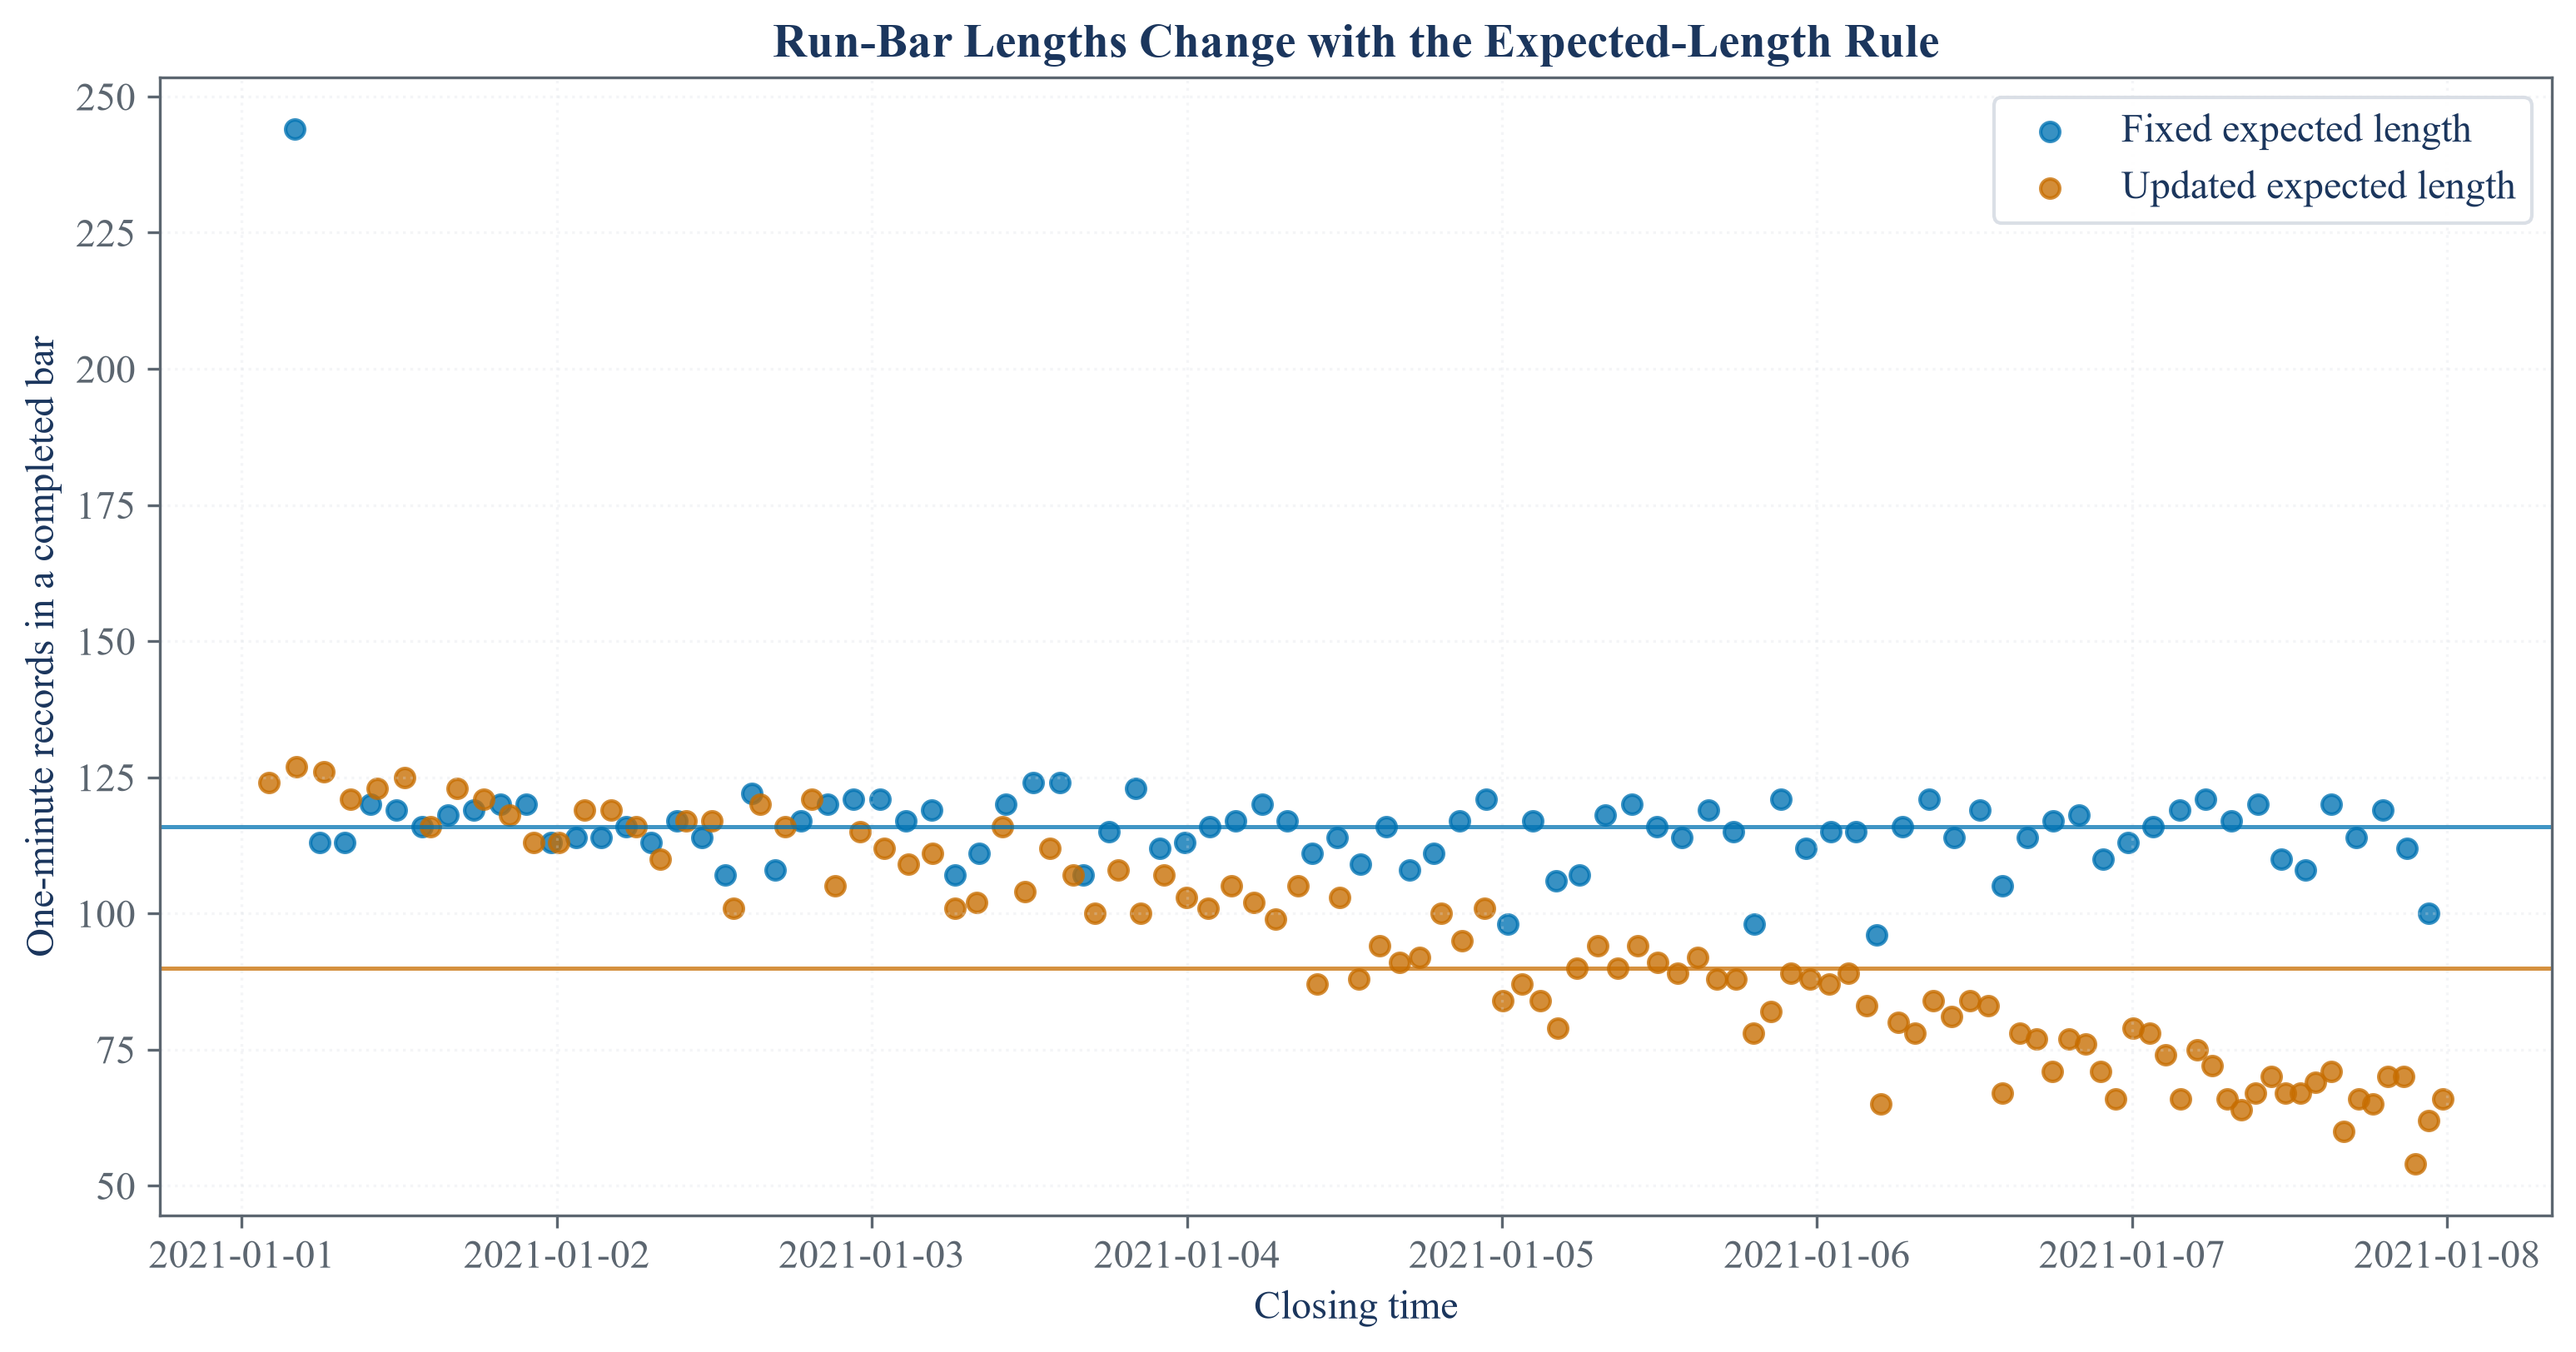

In [4]:
fixed_imbalance_rule = FixedImbalanceBars(
    "tick_imbalance",
    initial_estimate_of_expected_n_ticks_in_bar=120,
    window_size_for_expected_imbalance_estimation=240,
)
fixed_imbalance_bars = bar_frame(fixed_imbalance_rule.construct_bars_from_data(observations))

def comparison_row(name, frame):
    return {
        "Rule": name,
        "Complete bars": len(frame),
        "10th percentile records": frame["Records"].quantile(0.10),
        "Middle records": frame["Records"].median(),
        "90th percentile records": frame["Records"].quantile(0.90),
        "Records used by complete bars": frame["Records"].sum(),
    }

imbalance_run_comparison = pd.DataFrame([
    comparison_row("Fixed tick imbalance", fixed_imbalance_bars),
    comparison_row("Fixed tick run", fixed_run_bars),
])
save_table(imbalance_run_comparison, "imbalance_run_comparison", "Fixed tick-imbalance and tick-run rules applied to the same records.", "tab:imbalance-run-comparison")
display(imbalance_run_comparison.round(4))

figure, axis = plt.subplots(figsize=(10.2, 5.3), constrained_layout=True)
axis.scatter(fixed_run_bars["Time"], fixed_run_bars["Records"], color=palette["cyan"], s=30, alpha=0.78, label="Fixed expected length")
axis.scatter(expected_run_bars["Time"], expected_run_bars["Records"], color=palette["amber"], s=30, alpha=0.78, label="Updated expected length")
axis.axhline(fixed_run_bars["Records"].median(), color=palette["cyan"], linewidth=1.2, alpha=0.75)
axis.axhline(expected_run_bars["Records"].median(), color=palette["amber"], linewidth=1.2, alpha=0.75)
axis.set_xlabel("Closing time")
axis.set_ylabel("One-minute records in a completed bar")
axis.set_title("Run-Bar Lengths Change with the Expected-Length Rule")
axis.grid(True, alpha=0.28)
axis.legend()
figure.savefig(FIGURES / "run_bar_lengths.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "run_bar_lengths.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "run_bar_lengths.png")))
plt.close(figure)

In [5]:
fixed_close_positions = fixed_run_bars["Last record"].astype(int).to_numpy() - 1
close_crossings = []
previous_steps_below = []
bar_start = 0
for close_position in fixed_close_positions:
    row = fixed_run_history.iloc[close_position]
    boundary = row[EXPECTED_TICKS_NUMBER] * max(
        row[EXPECTED_BUY_TICKS_PROPORTION] * row[EXPECTED_BUY_IMBALANCE],
        (1.0 - row[EXPECTED_BUY_TICKS_PROPORTION]) * row[EXPECTED_SELL_IMBALANCE],
    )
    run_value = max(row[CUMULATIVE_BUY_THETA], row[CUMULATIVE_SELL_THETA])
    close_crossings.append(run_value >= boundary)
    if close_position > bar_start:
        prior = fixed_run_history.iloc[close_position - 1]
        prior_inputs = prior[[EXPECTED_TICKS_NUMBER, EXPECTED_BUY_TICKS_PROPORTION, EXPECTED_BUY_IMBALANCE, EXPECTED_SELL_IMBALANCE]].to_numpy(dtype=float)
        if np.isfinite(prior_inputs).all():
            prior_boundary = prior[EXPECTED_TICKS_NUMBER] * max(
                prior[EXPECTED_BUY_TICKS_PROPORTION] * prior[EXPECTED_BUY_IMBALANCE],
                (1.0 - prior[EXPECTED_BUY_TICKS_PROPORTION]) * prior[EXPECTED_SELL_IMBALANCE],
            )
            prior_value = max(prior[CUMULATIVE_BUY_THETA], prior[CUMULATIVE_SELL_THETA])
            previous_steps_below.append(prior_value < prior_boundary)
        else:
            previous_steps_below.append(True)
    bar_start = close_position + 1

## Tests

In [6]:
assert signs.size == 24
assert net_imbalance[-1] == 0
assert run_measure[-1] == 12
assert np.all(np.diff(positive_count) >= 0)
assert np.all(np.diff(negative_count) >= 0)
assert np.all(np.diff(run_measure) >= 0)
assert np.all(np.abs(net_imbalance) <= run_measure)
assert len(fixed_run_history) == len(raw)
assert len(expected_run_history) == len(raw)
assert len(fixed_run_bars) == 86
assert len(expected_run_bars) == 109
assert len(fixed_imbalance_bars) == 173
assert all(close_crossings)
assert all(previous_steps_below)
assert fixed_run_bars["Records"].min() >= 1
assert expected_run_bars["Records"].min() >= 1
assert fixed_run_bars["Rule level"].gt(0.0).all()
assert expected_run_bars["Rule level"].gt(0.0).all()
assert fixed_run_history[EXPECTED_TICKS_NUMBER].dropna().eq(120.0).all()
assert expected_run_history[EXPECTED_TICKS_NUMBER].dropna().between(20.0, 180.0).all()
assert (FIGURES / "imbalance_and_run_paths.pdf").exists()
assert (FIGURES / "run_bar_lengths.pdf").exists()
assert (TABLES / "controlled_run_comparison.tex").exists()
assert (TABLES / "run_bar_summary.tex").exists()
assert (TABLES / "imbalance_run_comparison.tex").exists()